# Linear Regression

## Simple linear regression

### Dataset description and visualisation

<b>Student Hours & Scores: </b> In this regression task we will predict the percentage of marks that a student is expected to score based upon the number of hours they studied.

<div class="alert alert-block alert-danger"> 

1. Import the student hours and scores dataset.
2. Is this task a multiple or a simple linear regression problem?
3. Which variable represents the dependent variable, and which one represents the independent variable?
4. Display the number of samples and features in the dataset.
5. Display the information about the dataset features.
6. Describe the features by displaying their statistics.
7. Plot the data and observe whether it demonstrates linear separability.
<div/>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Import the dataset
df = pd.read_csv("student_scores.csv")
df.head()

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30


Samples: 25
Features: 1
Shape: (25, 2)
info
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Hours   25 non-null     float64
 1   Scores  25 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 532.0 bytes
stats


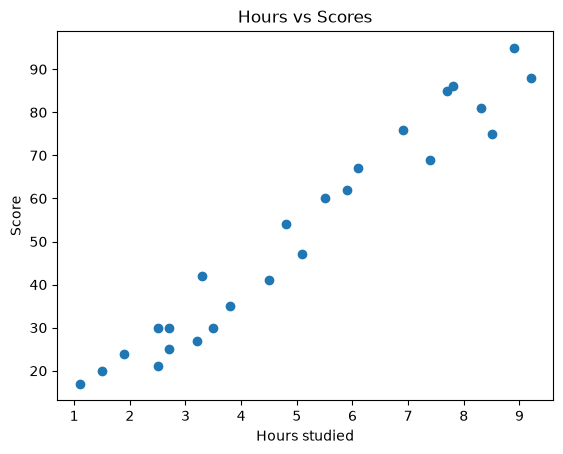

In [3]:
# 4. Number of samples and features
print("Samples:", df.shape[0])
print("Features:", df.shape[1] - 1)   # excluding the target column (Scores)
print("Shape:", df.shape)

# 5. Information about the features
print("info")
df.info()

# 6. Statistics
print("stats")
df.describe()

# 7. Plot the data
plt.scatter(df["Hours"], df["Scores"])
plt.xlabel("Hours studied")
plt.ylabel("Score")
plt.title("Hours vs Scores")
plt.show()

In [4]:
df.describe()

,Hours,Scores
count,25.000000,25.000000
mean,5.012000,51.480000
std,2.525094,25.286887
min,1.100000,17.000000
25%,2.700000,30.000000
50%,4.800000,47.000000
75%,7.400000,75.000000
max,9.200000,95.000000


Score = 9.68 * Hours + 2.83


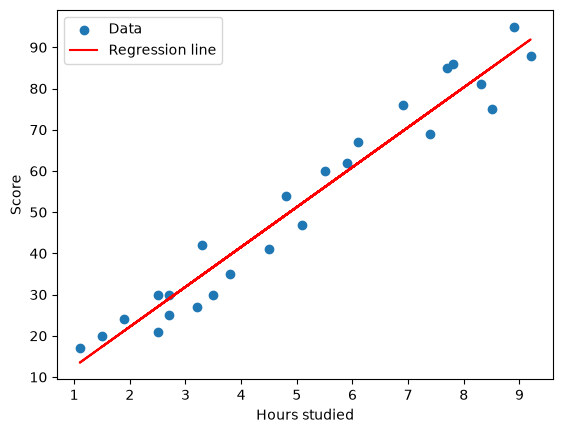

          Train       Test
MAE    5.221357   3.920751
MSE   31.454836  18.943212
RMSE   5.608461   4.352380
R2     0.949121   0.967806


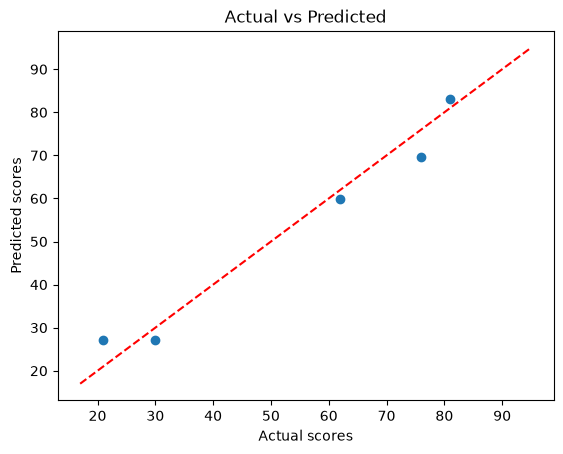

In [5]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[["Hours"]]
y = df["Scores"]

# 1. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Train
model = LinearRegression()
model.fit(X_train, y_train)

# 3. Equation
print(f"Score = {model.coef_[0]:.2f} * Hours + {model.intercept_:.2f}")

# 4. Plot data + model
plt.scatter(X, y, label="Data")
plt.plot(X, model.predict(X), color="red", label="Regression line")
plt.xlabel("Hours studied")
plt.ylabel("Score")
plt.legend()
plt.show()

# 5. Metrics on train and test
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

train_metrics = evaluate(y_train, model.predict(X_train))
test_metrics = evaluate(y_test, model.predict(X_test))
print(pd.DataFrame({"Train": train_metrics, "Test": test_metrics}))

# 8. Actual vs predicted
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")  # perfect prediction line
plt.xlabel("Actual scores")
plt.ylabel("Predicted scores")
plt.title("Actual vs Predicted")
plt.show()